# Support Vector Machine (SVM): Penyakit Daun Pisang

Dataset original dari `training/OriginalSet`; nama folder kelas dipakai sebagai label. Gambar diekstrak menjadi histogram warna RGB per kanal (16 bin), sehingga tiap gambar menjadi vektor 48 fitur. Ini fitur dasar untuk mempraktikkan model klasik, bukan representasi deep learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Find OriginalSet from project root or any parent of the notebook working directory.
DATA_DIR = next((parent / "training" / "OriginalSet" for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "training" / "OriginalSet").is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Dataset tidak ditemukan. Pastikan folder training/OriginalSet tersedia.")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
# A class directory is a leaf folder that directly contains images. This merges
# sources from nested dataset collections into the same disease label.
class_files = {}
for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        class_files.setdefault(path.parent.name, []).append(path)
class_names = sorted(class_files)
image_paths = [path for class_name in class_names for path in sorted(class_files[class_name])]
labels = [label for label, class_name in enumerate(class_names) for _ in sorted(class_files[class_name])]
print("Sumber:", DATA_DIR)
print("Kelas:", class_names)
print("Jumlah gambar per kelas:", {name: len(class_files[name]) for name in class_names})

Sumber: c:\PBL-KEL4_TI3C_SEM5\training\OriginalSet
Kelas: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']
Jumlah gambar per kelas: {'cordana': 262, 'healthy': 236, 'pestalotiopsis': 290, 'sigatoka': 573}


## Pra-pemrosesan Citra
Baca setiap file sebagai RGB, ubah ukurannya menjadi 64 x 64 piksel, lalu skala intensitas dari 0-255 menjadi 0-1. Gambar yang gagal dibaca dilewati dan dicatat. Tahapan ini menyiapkan representasi citra sebelum fitur dihitung.

In [2]:
preprocessed_images, valid_paths, valid_labels = [], [], []
for path, label in zip(image_paths, labels):
    try:
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("RGB").resize((64, 64)), dtype=np.float32) / 255.0
        preprocessed_images.append(pixels)
        valid_paths.append(path)
        valid_labels.append(label)
    except (OSError, ValueError):
        print("Lewati gambar rusak:", path)
image_paths = valid_paths
y = np.asarray(valid_labels)
print("Jumlah citra setelah preprocessing:", len(preprocessed_images))
print("Rentang nilai piksel:", min(float(img.min()) for img in preprocessed_images), "sampai", max(float(img.max()) for img in preprocessed_images))

c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\JpegImagePlugin.py:874: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Jumlah citra setelah preprocessing: 1361
Rentang nilai piksel: 0.0 sampai 1.0


## Ekstraksi Fitur
Setiap kanal warna R, G, dan B diringkas menjadi histogram 16 bin. Tiga histogram digabungkan menjadi 48 fitur numerik untuk setiap gambar. Fitur ini yang menjadi masukan bagi model klasik.

In [3]:
features = []
for pixels in preprocessed_images:
    feature = np.concatenate([np.histogram(pixels[:, :, ch], bins=16, range=(0, 1), density=True)[0] for ch in range(3)])
    features.append(feature)
X = np.asarray(features)
print("Bentuk matriks fitur:", X.shape)
print("Target kelas:", class_names)

Bentuk matriks fitur: (1361, 48)
Target kelas: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']


## Pembagian data
Split stratifikasi mempertahankan proporsi kelas. Semua preprocessing di-fit hanya pada data train.

In [4]:
train_indices, test_indices = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1088, 48) Test: (273, 48)


## Preprocessing Fitur di Pipeline
Imputasi median dan standardisasi dijalankan dalam pipeline, sehingga statistik preprocessing hanya dipelajari dari data training.
Langkah ini berbeda dari pra-pemrosesan citra di atas: imputasi dan, bila digunakan, standardisasi diterapkan pada matriks fitur setelah split.

Akurasi: 0.7545787545787546
                precision    recall  f1-score   support

       cordana       0.78      0.74      0.76        53
       healthy       0.67      0.64      0.65        47
pestalotiopsis       0.62      0.71      0.66        58
      sigatoka       0.86      0.83      0.85       115

      accuracy                           0.75       273
     macro avg       0.73      0.73      0.73       273
  weighted avg       0.76      0.75      0.76       273



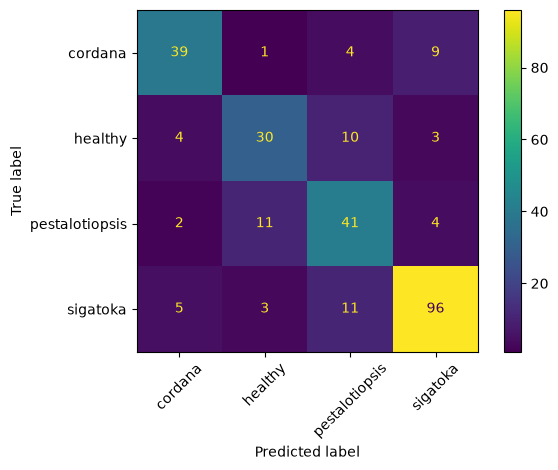

In [5]:
from sklearn.svm import SVC
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Akurasi:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, labels=np.arange(len(class_names)), target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=np.arange(len(class_names)), display_labels=class_names, xticks_rotation=45)
plt.tight_layout()
plt.show()

## Prediksi satu gambar dari test

In [6]:
sample_index = 0
print("File:", image_paths[test_indices[sample_index]])
print("Kelas aktual:", class_names[int(y_test[sample_index])])
print("Kelas prediksi:", class_names[int(model.predict(X_test[[sample_index]])[0])])

File: c:\PBL-KEL4_TI3C_SEM5\training\OriginalSet\sigatoka\341.jpeg
Kelas aktual: sigatoka
Kelas prediksi: sigatoka
